# 05 集中 GPU 验收（A → E，失败即停止）

本 Notebook 组织 A→C 的完整验收流程；模型命令分别由 `/content/.venv_planner/bin/python` 和 `/content/.venv/bin/python` 运行。每个阶段独立写入 ledger，前一阶段未通过时后一阶段会拒绝启动。Stage C 单元会显式安装固定 SmolVLA extra、下载固定 LIBERO checkpoint 并自动生成 smoke batch；不启动训练。D/E 的预算和命令保持未设置。

In [37]:
import json
import os
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import Image as DisplayImage, display

PROJECT_ROOT = Path("/content/vla-3d-trajectory-guidance").resolve()
CONFIG_PATH = PROJECT_ROOT / "configs" / "gpu_acceptance_colab.json"
acceptance_root = PROJECT_ROOT / "outputs" / "gpu_acceptance"

def find_resumable_run():
    candidates = []
    for ledger_path in acceptance_root.glob("*/acceptance_ledger.json"):
        try:
            state = json.loads(ledger_path.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError, KeyError):
            continue
        stages = state.get("stages", {})
        if stages.get("B", {}).get("status") == "passed" and stages.get("C", {}).get("status") != "passed":
            candidates.append((ledger_path.stat().st_mtime, ledger_path.parent))
    return max(candidates, default=(None, None))[1]

run_override = os.environ.get("VLA_GPU_ACCEPTANCE_RUN_DIR")
resumable_run = find_resumable_run() if not run_override else None
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = Path(
    run_override
    or resumable_run
    or acceptance_root / timestamp
).resolve()
RUN_DIR.mkdir(parents=True, exist_ok=True)

def run_command(command, *, env=None):
    command = list(map(str, command))
    print("$", " ".join(command), flush=True)
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        env=env,
    )
    lines = []
    assert process.stdout is not None
    for line in process.stdout:
        print(line, end="", flush=True)
        lines.append(line)
    returncode = process.wait()
    output = "".join(lines)
    if returncode:
        raise subprocess.CalledProcessError(returncode, command, output=output)
    return subprocess.CompletedProcess(command, returncode, stdout=output)

def run_stage(stage):
    return run_command([
        sys.executable,
        PROJECT_ROOT / "scripts" / "run_gpu_acceptance_stage.py",
        "--stage", stage,
        "--project-root", PROJECT_ROOT,
        "--config", CONFIG_PATH,
        "--run-dir", RUN_DIR,
    ])

print(f"Run directory: {RUN_DIR}")
if resumable_run is not None:
    print("已自动续接最新的 B=passed、C!=passed 验收目录。")
print("默认输出位于临时 /content；长训练开始后再把 RUN_DIR 指向已挂载的 Google Drive。")

Run directory: /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z
已自动续接最新的 B=passed、C!=passed 验收目录。
默认输出位于临时 /content；长训练开始后再把 RUN_DIR 指向已挂载的 Google Drive。


## 阶段 A：环境、checkpoint、缓存与标定

不加载大模型。分别用两个目标解释器检查固定依赖与 CUDA，并重新读取已保存的 RGB-D、K、外参和 checkpoint manifest。

In [38]:
planner_npp = "/content/.venv_planner/lib/python3.12/site-packages/nvidia/npp/lib"
paths = [p for p in os.environ.get("LD_LIBRARY_PATH", "").split(":") if p]
os.environ["LD_LIBRARY_PATH"] = ":".join(
    [planner_npp, *(p for p in paths if p != planner_npp)]
)

run_stage("A")

$ /usr/bin/python3 /content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py --stage A --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --run-dir /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z
Stage A already passed; leaving recorded evidence unchanged.


CompletedProcess(args=['/usr/bin/python3', '/content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py', '--stage', 'A', '--project-root', '/content/vla-3d-trajectory-guidance', '--config', '/content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json', '--run-dir', '/content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z'], returncode=0, stdout='Stage A already passed; leaving recorded evidence unchanged.\n')

In [39]:
ledger = json.loads((RUN_DIR / "acceptance_ledger.json").read_text(encoding="utf-8"))
print(json.dumps(ledger["stages"]["A"], ensure_ascii=False, indent=2))
assert ledger["stages"]["A"]["status"] == "passed"

{
  "status": "passed",
  "attempts": 1,
  "started_at_utc": "2026-11-01T11:55:46.458947+00:00",
  "completed_at_utc": "2026-11-01T11:55:58.629926+00:00",
  "failure": null,
  "metrics": {
    "planner_gpu": {
      "available": true,
      "index": 0,
      "name": "NVIDIA A100-SXM4-40GB",
      "total_memory_bytes": 42405855232,
      "torch_cuda_build": "12.8",
      "allocated_bytes": 0,
      "reserved_bytes": 0,
      "peak_allocated_bytes": 0,
      "peak_reserved_bytes": 0
    },
    "smolvla_gpu": {
      "available": true,
      "index": 0,
      "name": "NVIDIA A100-SXM4-40GB",
      "total_memory_bytes": 42405855232,
      "torch_cuda_build": "12.8"
    },
    "input_depth_validation": {
      "valid": true,
      "errors": [],
      "warnings": [],
      "metrics": {
        "shape": [
          256,
          256
        ],
        "dtype": "float32",
        "finite_fraction": 1.0,
        "valid_fraction": 1.0,
        "accepted_depth_range_m": [
          0.01,
       

## 阶段 B：LIBERO 单帧真实高层规划

只在 A 通过后加载一次 3D HAMSTER。输出 UVD、camera/world XYZ、几何诊断、overlay 和统一轨迹缓存。若几何无效，阶段 B 失败并阻止 C。

In [40]:
run_stage("B")

$ /usr/bin/python3 /content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py --stage B --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --run-dir /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z
Stage B already passed; leaving recorded evidence unchanged.


CompletedProcess(args=['/usr/bin/python3', '/content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py', '--stage', 'B', '--project-root', '/content/vla-3d-trajectory-guidance', '--config', '/content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json', '--run-dir', '/content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z'], returncode=0, stdout='Stage B already passed; leaving recorded evidence unchanged.\n')

{
  "valid": true,
  "waypoint_count": 3,
  "timing_seconds": {
    "model_load": 10.07407824300003,
    "inference": 6.444294056999979
  },
  "geometry_validation": {
    "valid": true,
    "errors": [],
    "warnings": [
      "planner depth differs from the observed surface depth by more than 0.25 m at one or more pixels; this is diagnostic only because 3D waypoints may lie in free space"
    ],
    "metrics": {
      "waypoint_count": 3,
      "projection_roundtrip_max_abs_error": 1.1368683772161603e-13,
      "rigid_segment_length_max_abs_error_m": 1.1102230246251565e-16,
      "camera_xyz_range_m": {
        "x": [
          0.21032936270181027,
          0.3064517619861107
        ],
        "y": [
          -0.04006273575272575,
          0.1484541407545173
        ],
        "z": [
          0.93,
          1.28
        ]
      },
      "world_xyz_range_m": {
        "x": [
          -0.24395584353777278,
          -0.09009528008235179
        ],
        "y": [
          0.210

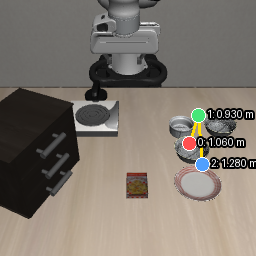

In [41]:
ledger = json.loads((RUN_DIR / "acceptance_ledger.json").read_text(encoding="utf-8"))
stage_b_summary_path = Path(ledger["stages"]["B"]["artifacts"]["summary"])
stage_b_summary = json.loads(stage_b_summary_path.read_text(encoding="utf-8"))
print(json.dumps({
    "valid": stage_b_summary["valid"],
    "waypoint_count": stage_b_summary["waypoint_count"],
    "timing_seconds": stage_b_summary["timing_seconds"],
    "geometry_validation": stage_b_summary["geometry_validation"],
    "trajectory_cache_record": stage_b_summary["artifacts"]["trajectory_cache_record"],
}, ensure_ascii=False, indent=2))
overlay = Path(stage_b_summary["artifacts"]["trajectory_overlay_png"])
if overlay.is_file():
    display(DisplayImage(filename=str(overlay)))
assert stage_b_summary["valid"] is True

## 阶段 C：真实 SmolVLA E0/E1/E2 冒烟

直接运行下一单元。它会在 `/content/.venv` 安装固定 commit 的 `smolvla` extra，核对所有受保护版本，断点续传固定的 `lerobot/smolvla_libero` checkpoint，并从 Stage B 的真实观测和预测轨迹自动生成因果 smoke batch。随后执行 E0/E1/E2 的真实 forward/backward、梯度、动作维度与显存检查；不做 optimizer step、训练或 rollout。零 action target 与缺失 gripper 的零填充只用于接口冒烟，输出会明确标记为非训练数据。

In [44]:
ledger = json.loads((RUN_DIR / "acceptance_ledger.json").read_text(encoding="utf-8"))
assert ledger["stages"]["B"]["status"] == "passed", "Stage B 尚未通过"

stage_c_root = RUN_DIR / "stage_c_inputs"
stage_c_environment = stage_c_root / "smolvla_environment.json"
stage_c_inputs = stage_c_root / "stage_c_inputs.json"

run_command([
    sys.executable,
    PROJECT_ROOT / "scripts" / "bootstrap_smolvla_env.py",
    "--project-root", PROJECT_ROOT,
    "--config", CONFIG_PATH,
    "--output", stage_c_environment,
])

smolvla_env = os.environ.copy()
smolvla_npp = "/content/.venv/lib/python3.12/site-packages/nvidia/npp/lib"
loader_paths = [p for p in smolvla_env.get("LD_LIBRARY_PATH", "").split(":") if p]
smolvla_env["LD_LIBRARY_PATH"] = ":".join(
    [smolvla_npp, *(p for p in loader_paths if p != smolvla_npp)]
)
run_command([
    "/content/.venv/bin/python",
    PROJECT_ROOT / "scripts" / "prepare_smolvla_stage_c_inputs.py",
    "--project-root", PROJECT_ROOT,
    "--config", CONFIG_PATH,
    "--run-dir", RUN_DIR,
    "--output", stage_c_inputs,
], env=smolvla_env)

prepared = json.loads(stage_c_inputs.read_text(encoding="utf-8"))
assert prepared["valid"] is True
os.environ["VLA_SMOLVLA_POLICY_PATH"] = prepared["policy_path"]
os.environ["VLA_SMOLVLA_BATCH_ARTIFACT"] = prepared["batch_artifact"]
os.environ["LD_LIBRARY_PATH"] = smolvla_env["LD_LIBRARY_PATH"]
run_stage("C")

$ /usr/bin/python3 /content/vla-3d-trajectory-guidance/scripts/bootstrap_smolvla_env.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --output /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z/stage_c_inputs/smolvla_environment.json

$ /usr/local/bin/uv pip install --python /content/.venv/bin/python --torch-backend cu128 --no-sources --constraint /content/vla-3d-trajectory-guidance/configs/libero_constraints.txt --editable /content/third_party/lerobot[libero,smolvla]
Resolved 164 packages in 22ms
Prepared 1 package in 1.02s
Uninstalled 1 package in 0.80ms
Installed 1 package in 3ms
 ~ lerobot==0.6.2 (from file:///content/third_party/lerobot)

$ /usr/local/bin/uv pip check --python /content/.venv/bin/python
Checked 166 packages in 2ms
All installed packages are compatible
{
  "schema_version": 1,
  "created_at_utc": "2026-11-01T12:15:35.475601+00:00",
  "valid": true,
  "scope":

CompletedProcess(args=['/usr/bin/python3', '/content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py', '--stage', 'C', '--project-root', '/content/vla-3d-trajectory-guidance', '--config', '/content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json', '--run-dir', '/content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z'], returncode=0, stdout='$ /content/.venv/bin/python /content/vla-3d-trajectory-guidance/scripts/run_smolvla_real_smoke.py --project-root /content/vla-3d-trajectory-guidance --policy-path /content/models/smolvla_libero/a24f1f380461b665158d52acd140152c79e8b36d --batch-artifact /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z/stage_c_inputs/smoke_batch --device cuda:0 --output /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z/stage_c/attempt_001/smolvla_smoke.json\nReducing the number of VLM layers to 16 ...\nLoading weights from local directory\n{\n  "schema_version": 1,\n  "

## 阶段 D：自动单任务小规模验证

D 已配置为自动、受限且失败即停止：先在固定 `lerobot/libero` revision 中匹配 Stage B 的语言、EEF 与双相机初始观测；匹配通过后，E0/E1/E2 各自从同一 checkpoint 开始，使用同一真实 action chunk 完成 2 个 optimizer step 和 1 次 task0/init0 rollout。无需手填 policy、dataset 或 batch 路径。该阶段只验证真实数据、优化器和闭环接口，不把 loss 或单次成功与否当作模型效果。E 仍保持禁用。

In [49]:
try:
    run_stage("D")
except subprocess.CalledProcessError:
    failed_ledger = json.loads((RUN_DIR / "acceptance_ledger.json").read_text(encoding="utf-8"))
    failed_attempt = int(failed_ledger["stages"]["D"]["attempts"])
    failed_pilot = RUN_DIR / "stage_d" / f"attempt_{failed_attempt:03d}" / "pilot"
    for diagnostic_name in ("task_match.json", "observation_match.json"):
        diagnostic_path = failed_pilot / diagnostic_name
        if diagnostic_path.is_file():
            print(f"\n===== {diagnostic_name} =====")
            print(diagnostic_path.read_text(encoding="utf-8"))
    raise
else:
    print("Stage E 仍未配置；Stage D 通过后也不会自动启动正式实验。")

$ /usr/bin/python3 /content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py --stage D --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --run-dir /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z
$ /content/.venv/bin/python /content/vla-3d-trajectory-guidance/scripts/run_stage_d_single_task_pilot.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --run-dir /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z --output-dir /content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z/stage_d/attempt_004/pilot
$ /content/.venv/bin/python /content/vla-3d-trajectory-guidance/scripts/prepare_smolvla_stage_d_inputs.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json --run-dir /

CalledProcessError: Command '['/usr/bin/python3', '/content/vla-3d-trajectory-guidance/scripts/run_gpu_acceptance_stage.py', '--stage', 'D', '--project-root', '/content/vla-3d-trajectory-guidance', '--config', '/content/vla-3d-trajectory-guidance/configs/gpu_acceptance_colab.json', '--run-dir', '/content/vla-3d-trajectory-guidance/outputs/gpu_acceptance/20261101T115541Z']' returned non-zero exit status 1.

In [ ]:
ledger = json.loads((RUN_DIR / "acceptance_ledger.json").read_text(encoding="utf-8"))
print(json.dumps({stage: record["status"] for stage, record in ledger["stages"].items()}, ensure_ascii=False, indent=2))